# GTDB IS110s
I used the sternberg + bernheim HMM to find IS110s in GTDB. I filtered to make
sure the hits have the required domains. Here, I want to explore these results.

In [1]:
%cd /groups/cress/projects/efactors/jack/insertion_mapping/data/gtdb_search/full_hmm
from Bio import SeqIO
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from extract_is110s import read_domtblout
from plotnine import *
from matplotlib import cm
from matplotlib.colors import to_hex

/groups/cress/projects/efactors/jack/insertion_mapping/data/gtdb_search/full_hmm


In [2]:
domains = read_domtblout("is110s_clustered_rep_seq.domtbl")
domains = domains[domains["full_evalue"] <= 1e-3] 

In [3]:
records = SeqIO.parse("true_is110s_clustered_rep_seq.faa", "fasta")
is110s = [record.id for record in records]
is110_domains = domains[domains["query_name"].isin(is110s)]
hmmsearch_df = pd.read_csv("gtdb_is110s.domtbl.csv", index_col=0)
hmmsearch_df = hmmsearch_df[hmmsearch_df["target_name"].isin(is110s)]


In [4]:
cluster_info = pd.read_csv("is110s_clustered_cluster.tsv", sep="\t", header=None)
cluster_info.columns = ["rep", "member"]
cluster_sizes = cluster_info["rep"].value_counts()
cluster_info.head()

,rep,member
0,NZ_CP070977.1_1282,NZ_CP070977.1_1282
1,NZ_CP070977.1_404,NZ_CP070977.1_404
2,NZ_CP070978.1_2532,NZ_CP070978.1_2532
3,NZ_CP070979.1_278,NZ_CP070979.1_278
4,JAUIJB010000025.1_3,JAUIJB010000025.1_3


In [5]:
from plotnine import *
from matplotlib import cm
from matplotlib.colors import to_hex

# Copy and prepare data
hits = is110_domains[is110_domains["full_evalue"] <= 1e-3].copy()
# Create a hit description + hit id column for the legend
hits['hitname'] = hits['description'] + " (" + hits['target_name'] + ")"
# # Transfer seq length
hits['tlen'] = hits['query_name'].map(dict(hmmsearch_df[['target_name', 'tlen']].values))
# # Remove sequences that are duplicates of each other
# hits = hits[hits['query_name'].isin(df.drop_duplicates(subset='tseq')["seqtag"])]
# Subset to only sequences that have more than just the 2 domains I used to filter (or those w duplicates of any of these)
unique_profile_ct = hits.groupby('query_name')['target_name'].apply(len)
additional_domains = unique_profile_ct[unique_profile_ct > 2].keys()
hits = hits[
    (hits['query_name'].isin(additional_domains))
    & (hits['tlen'] >= 500)]
hits = hits.sort_values(by=['tlen', 'query_name'], ascending=False)
hits[['env_start', 'env_end']] = hits[['env_start', 'env_end']].astype(int)
# # Get tlen for each seqtag from df
# seq_lengths = df.set_index('seqtag')['tlen'].to_dict()
# hits['tlen'] = hits['query_name'].map(seq_lengths)
# Plotting stuff
cmap1 = cm.get_cmap('tab20')
cmap2 = cm.get_cmap('tab20b')

colors1 = [to_hex(cmap1(i)) for i in range(cmap1.N)]
colors2 = [to_hex(cmap2(i)) for i in range(cmap2.N)]

palette_34 = colors1 + colors2[:14]

/tmp/ipykernel_3270610/3598532372.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
/tmp/ipykernel_3270610/3598532372.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.


90% cluster sizes:
NZ_JAERLY010000035.1_4: 1
NC_016037.1_170: 6
NZ_HG916853.1_122: 1
CADCTL010000278.1_1: 1


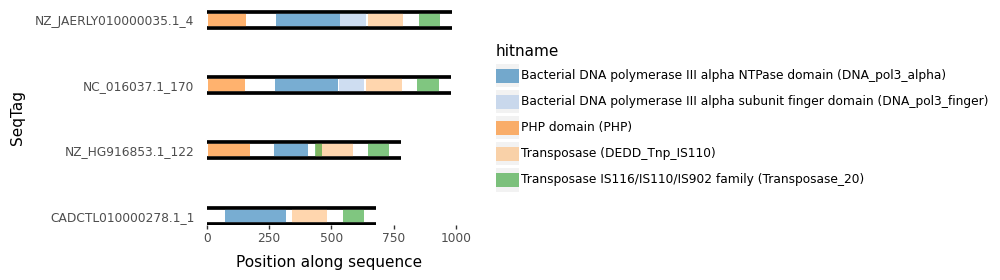

In [6]:
polymerase_hits = hits.loc[hits["description"].str.lower().str.contains("polymerase"), "query_name"].unique()
print("90% cluster sizes:")
for i in polymerase_hits:
    print(f"{i}: {cluster_sizes[i]}")

pol_hits = hits[hits["query_name"].isin(polymerase_hits)].copy()

unique_tags = pol_hits['query_name'].unique()
y_positions = {tag: i for i, tag in enumerate(reversed(unique_tags))}  # reversed for top-down
pol_hits['y'] = pol_hits['query_name'].map(y_positions)

p = (
    ggplot()
    # Background "white-filled black outline" bars for each seqtag
    + geom_segment(
        aes(x=0, xend='tlen', y='y', yend='y'), 
        size=8, color='black', data=pol_hits.drop_duplicates(subset='query_name')
    )
    + geom_segment(
        aes(x=0, xend='tlen', y='y', yend='y'), 
        size=5, color='white', data=pol_hits.drop_duplicates(subset='query_name')
    )
    # Alignment pol_hits
    + geom_segment(
        aes(x='env_start', xend='env_end', y='y', yend='y', color='hitname'), 
        alpha=0.6, size=5, data=pol_hits
    )
    + scale_color_manual(values=palette_34)
    # Theme and formatting
    + scale_y_continuous(
        breaks=list(y_positions.values()), 
        labels=list(y_positions.keys())
    )
    + labs(x="Position along sequence", y="SeqTag")
    + theme(
        figure_size=(10, 0.7 * len(unique_tags)),  # dynamic height
        axis_ticks_y=element_blank(),
        panel_background=element_blank(),
        panel_grid=element_blank(),
        panel_border=element_blank(),
        legend_position='right'
    )
    + guides(color=guide_legend(ncol=1))
)

p.draw()




In [7]:
def save_fusion(acc):
    with open (f"cool_fusions/{acc}.faa", "w") as f:
        to_save = []
        records = SeqIO.parse("true_is110s_clustered_rep_seq.faa", "fasta")
        for record in records:
            if record.id == acc:
                to_save.append(record)
        SeqIO.write(to_save, f, "fasta")
    


save_fusion("NC_016037.1_170")

In [8]:
domains[domains["query_name"]=="NC_016037.1_170"]

,target_name,target_accession,tlen,query_name,query_accession,qlen,full_evalue,full_score,full_bias,domain_num,...,domain_score,domain_bias,hmm_start,hmm_end,ali_start,ali_end,env_start,env_end,accuracy,description
229655,DNA_pol3_alpha,PF07733.17,260,NC_016037.1_170,-,978,2.100000e-84,283.5,0.0,1,...,282.9,0.0,2,260,274,527,273,527,0.96,Bacterial DNA polymerase III alpha NTPase domain
229656,DNA_pol3_finger,PF17657.6,166,NC_016037.1_170,-,978,5.800000e-27,94.3,0.0,1,...,93.3,0.0,1,83,530,612,530,631,0.96,Bacterial DNA polymerase III alpha subunit fin...
229657,Transposase_20,PF02371.21,87,NC_016037.1_170,-,978,1.300000e-26,93.0,0.3,1,...,91.7,0.3,2,82,845,926,844,930,0.94,Transposase IS116/IS110/IS902 family
229658,DEDD_Tnp_IS110,PF01548.22,155,NC_016037.1_170,-,978,4.200000e-16,59.4,0.0,1,...,57.9,0.0,1,149,640,777,640,781,0.92,Transposase
229659,PHP,PF02811.24,164,NC_016037.1_170,-,978,1.300000e-11,45.4,0.0,1,...,44.4,0.0,2,120,8,122,7,153,0.83,PHP domain


In [9]:
domains_per_hit = hits.groupby("query_name")["target_name"].value_counts()
important_domains = ["DEDD_Tnp_IS110", "Transposase_20"]
fusions = []

for q in hits["query_name"].unique():
    dq = domains_per_hit[q]
    if all([dq[i] > 1 for i in important_domains]):
        fusions.append(q)



In [10]:
fusions = [
    "NZ_LT605203.1_3827",
    "NZ_PKEK01000097.1_4",
    "NZ_LT605203.1_4173",
]

90% cluster sizes:
NZ_LT605203.1_3827: 1
NZ_PKEK01000097.1_4: 1
NZ_LT605203.1_4173: 1


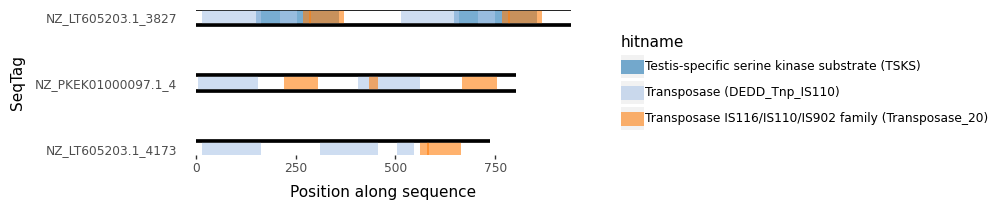

In [11]:
print("90% cluster sizes:")
for i in fusions:
    print(f"{i}: {cluster_sizes[i]}")

fusion_hits = hits[hits["query_name"].isin(fusions)].copy()

unique_tags = fusion_hits['query_name'].unique()
y_positions = {tag: i for i, tag in enumerate(reversed(unique_tags))}  # reversed for top-down
fusion_hits['y'] = fusion_hits['query_name'].map(y_positions)

p = (
    ggplot()
    # Background "white-filled black outline" bars for each seqtag
    + geom_segment(
        aes(x=0, xend='tlen', y='y', yend='y'), 
        size=8, color='black', data=fusion_hits.drop_duplicates(subset='query_name')
    )
    + geom_segment(
        aes(x=0, xend='tlen', y='y', yend='y'), 
        size=5, color='white', data=fusion_hits.drop_duplicates(subset='query_name')
    )
    # Alignment fusion_hits
    + geom_segment(
        aes(x='env_start', xend='env_end', y='y', yend='y', color='hitname'), 
        alpha=0.6, size=5, data=fusion_hits
    )
    + scale_color_manual(values=palette_34)
    # Theme and formatting
    + scale_y_continuous(
        breaks=list(y_positions.values()), 
        labels=list(y_positions.keys())
    )
    + labs(x="Position along sequence", y="SeqTag")
    + theme(
        figure_size=(10, 0.7 * len(unique_tags)),  # dynamic height
        axis_ticks_y=element_blank(),
        panel_background=element_blank(),
        panel_grid=element_blank(),
        panel_border=element_blank(),
        legend_position='right'
    )
    + guides(color=guide_legend(ncol=1))
)

p.draw()


